In [13]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '../src')
from cr3bp import (cr3bp_rhs, cr3bp_rhs_with_stm, integrate_with_stm,
                   find_lagrange_points, jacobi_constant, MU_EARTH_MOON)
from scipy.integrate import solve_ivp

mu = MU_EARTH_MOON
lps = find_lagrange_points(mu)


def y_axis_crossing(t, state, mu):
    """Event function: returns y. solve_ivp detects when this hits zero,
    i.e. when the trajectory crosses the x-axis."""
    return state[1]   # the y-component

# Tell solve_ivp about the event:
y_axis_crossing.terminal = True    # stop integrating when the event fires
y_axis_crossing.direction = -1     # only trigger on y going + -> - (downward crossing)

In [14]:
# A rough starting guess for a small L1 Lyapunov orbit.
# Start just to the left of L1 on the x-axis, moving in +y.
x0_guess = lps['L1'][0] - 0.01   # slightly inside L1
vy0_guess = 0.05                  # initial guess for perpendicular velocity

state0 = [x0_guess, 0.0, 0.0, vy0_guess]   # [x, y=0, vx=0, vy]

# Integrate until the x-axis crossing
sol = solve_ivp(cr3bp_rhs, (0, 10), state0, args=(mu,),
                method='DOP853', rtol=1e-12, atol=1e-12,
                events=y_axis_crossing, dense_output=True)

print(f"Integration status: {sol.message}")
print(f"Number of events found: {len(sol.t_events[0])}")
if len(sol.t_events[0]) > 0:
    t_cross = sol.t_events[0][0]
    state_cross = sol.y_events[0][0]
    print(f"\nCrossing time (half-period guess): {t_cross:.6f}")
    print(f"State at crossing: x={state_cross[0]:.6f}, y={state_cross[1]:.2e}, "
          f"vx={state_cross[2]:.6f}, vy={state_cross[3]:.6f}")
    print(f"\nThe residual we need to drive to zero: vx = {state_cross[2]:.6f}")

Integration status: A termination event occurred.
Number of events found: 1

Crossing time (half-period guess): 2.628390
State at crossing: x=-0.429913, y=1.20e-16, vx=-0.633848, vy=-1.158669

The residual we need to drive to zero: vx = -0.633848


In [15]:
import numpy as np
import sys
sys.path.insert(0, '../src')
from cr3bp import cr3bp_jacobian, find_lagrange_points, MU_EARTH_MOON

mu = MU_EARTH_MOON
lps = find_lagrange_points(mu)

# The L1 point as a full state (on x-axis, at rest)
L1_state = [lps['L1'][0], 0.0, 0.0, 0.0]

# Jacobian at L1
A_L1 = cr3bp_jacobian(L1_state, mu)
print("Jacobian at L1:")
print(A_L1)
print()

# Its eigenvalues
eigvals = np.linalg.eigvals(A_L1)
print("Eigenvalues at L1:")
for ev in eigvals:
    print(f"  {ev:.6f}")

Jacobian at L1:
[[ 0.          0.          1.          0.        ]
 [ 0.          0.          0.          1.        ]
 [11.29518908  0.          0.          2.        ]
 [ 0.         -4.14759454 -2.          0.        ]]

Eigenvalues at L1:
  -2.932056+0.000000j
  2.932056+0.000000j
  0.000000+2.334386j
  0.000000-2.334386j


In [16]:
# Get eigenvalues AND eigenvectors
eigvals, eigvecs = np.linalg.eig(A_L1)

# Find the eigenvalue with POSITIVE imaginary part (the +i*omega one)
imag_idx = np.argmax(eigvals.imag)   # index of the most-positive-imaginary eigenvalue
omega = eigvals[imag_idx].imag
print(f"Oscillation frequency omega = {omega:.6f}")
print(f"Linearized orbit period T = {2*np.pi/omega:.6f}")
print()

# The corresponding (complex) eigenvector
v = eigvecs[:, imag_idx]
print("Complex eigenvector for +i*omega:")
print(f"  x-component:  {v[0]:.6f}")
print(f"  y-component:  {v[1]:.6f}")
print(f"  vx-component: {v[2]:.6f}")
print(f"  vy-component: {v[3]:.6f}")

Oscillation frequency omega = 2.334386
Linearized orbit period T = 2.691580

Complex eigenvector for +i*omega:
  x-component:  -0.105758-0.000000j
  y-component:  0.000000-0.379301j
  vx-component: -0.000000-0.246880j
  vy-component: 0.885435+0.000000j


In [17]:
# Extract the real parts that define the symmetric initial condition
x_comp = v[0].real      # -0.105758
vy_comp = v[3].real     #  0.885435

# The ratio of vy0 to x-offset for the linearized Lyapunov orbit
ratio = vy_comp / x_comp
print(f"vy0 / delta_x ratio = {ratio:.6f}")

# Choose a small orbit: offset x from L1 by a small amount.
# Sign convention: let's offset to the LEFT of L1 (toward Earth), delta_x < 0,
# which makes vy0 positive. Small magnitude = small orbit = closer to linear.
delta_x = -0.001
x0 = lps['L1'][0] + delta_x
vy0 = ratio * delta_x

print(f"\nLinearized initial guess for a small L1 Lyapunov orbit:")
print(f"  x0  = {x0:.8f}   (L1 offset by {delta_x})")
print(f"  y0  = 0.0")
print(f"  vx0 = 0.0")
print(f"  vy0 = {vy0:.8f}")

# Sanity check: integrate this guess to the x-axis crossing and see the residual.
# If the linearization is good, the residual vx should be SMALL (unlike the 0.63 before).
from scipy.integrate import solve_ivp
from cr3bp import cr3bp_rhs

def y_axis_crossing(t, state, mu):
    return state[1]
y_axis_crossing.terminal = True
y_axis_crossing.direction = -1

state0 = [x0, 0.0, 0.0, vy0]
sol = solve_ivp(cr3bp_rhs, (0, 10), state0, args=(mu,),
                method='DOP853', rtol=1e-12, atol=1e-12,
                events=y_axis_crossing)

if len(sol.t_events[0]) > 0:
    state_cross = sol.y_events[0][0]
    t_cross = sol.t_events[0][0]
    print(f"\nHalf-period crossing at t = {t_cross:.6f} (linear prediction: {np.pi/omega:.6f})")
    print(f"  x at crossing  = {state_cross[0]:.8f}")
    print(f"  vx at crossing = {state_cross[2]:.8e}   <- residual to correct")
else:
    print("\nNo crossing found — check the guess.")

vy0 / delta_x ratio = -8.372273

Linearized initial guess for a small L1 Lyapunov orbit:
  x0  = 0.83591513   (L1 offset by -0.001)
  y0  = 0.0
  vx0 = 0.0
  vy0 = 0.00837227

Half-period crossing at t = 1.359022 (linear prediction: 1.345790)
  x at crossing  = 0.83769049
  vx at crossing = -7.57724319e-04   <- residual to correct


In [18]:
def correct_lyapunov_orbit(x0, vy0_guess, mu, tol=1e-11, max_iter=20, verbose=True):
    """Differential corrector for a planar Lyapunov orbit via single shooting.

    Fixes x0; adjusts vy0 so that vx = 0 at the perpendicular x-axis crossing
    (the half-period). Uses the STM for a Newton correction, with the
    moving-crossing-time correction term.

    Returns the corrected vy0, the half-period, and the converged crossing state.
    """
    vy0 = vy0_guess

    for iteration in range(max_iter):
        # Integrate WITH the STM until the x-axis crossing
        state0 = [x0, 0.0, 0.0, vy0]

        def crossing_event(t, aug, mu):
            return aug[1]   # y-component
        crossing_event.terminal = True
        crossing_event.direction = -1

        sol = integrate_with_stm(state0, (0, 10), mu, events=crossing_event)

        if len(sol.t_events[0]) == 0:
            raise RuntimeError("No x-axis crossing found during correction.")

        # State and STM at the crossing
        aug_cross = sol.y_events[0][0]
        state_cross = aug_cross[:4]
        Phi = aug_cross[4:].reshape(4, 4)

        vx_cross = state_cross[2]   # the residual we want to zero

        if verbose:
            print(f"  iter {iteration}: vy0={vy0:.12f}, residual vx={vx_cross:.3e}")

        # Converged?
        if abs(vx_cross) < tol:
            half_period = sol.t_events[0][0]
            if verbose:
                print(f"  Converged: vx residual {vx_cross:.2e} < tol {tol:.0e}")
            return vy0, half_period, state_cross

        # --- Newton correction with moving-time term ---
        # Derivatives at the crossing (from equations of motion)
        deriv = cr3bp_rhs(0, state_cross, mu)
        ydot = deriv[1]        # d(y)/dt at crossing
        vxdot = deriv[2]       # d(vx)/dt at crossing

        # Corrected sensitivity: d(vx_cross)/d(vy0)
        # Phi[2,3] = sensitivity of vx (idx 2) to initial vy (idx 3)
        # Phi[1,3] = sensitivity of y  (idx 1) to initial vy (idx 3)
        sensitivity = Phi[2, 3] - (vxdot / ydot) * Phi[1, 3]

        # Newton step
        delta_vy0 = -vx_cross / sensitivity
        vy0 = vy0 + delta_vy0

    raise RuntimeError(f"Did not converge in {max_iter} iterations.")

In [19]:
vy0_corrected, half_period, crossing = correct_lyapunov_orbit(x0, vy0, mu)

print(f"\nCorrected vy0 = {vy0_corrected:.12f}")
print(f"Half-period   = {half_period:.8f}")
print(f"Full period   = {2*half_period:.8f}")
print(f"Residual vx at crossing = {crossing[2]:.2e}")

  iter 0: vy0=0.008372273268, residual vx=-7.577e-04
  iter 1: vy0=0.008432503148, residual vx=-2.780e-05
  iter 2: vy0=0.008434882189, residual vx=-3.807e-08
  iter 3: vy0=0.008434885455, residual vx=-6.495e-14
  Converged: vx residual -6.50e-14 < tol 1e-11

Corrected vy0 = 0.008434885455
Half-period   = 1.34589505
Full period   = 2.69179009
Residual vx at crossing = -6.50e-14


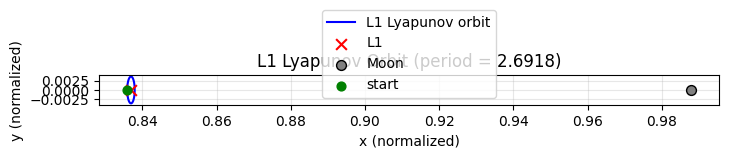

Closure error (should be tiny): 1.60e-11


In [20]:
# Integrate the converged orbit for one full period
state0 = [x0, 0.0, 0.0, vy0_corrected]
full_period = 2 * half_period

sol_orbit = solve_ivp(cr3bp_rhs, (0, full_period), state0, args=(mu,),
                      method='DOP853', rtol=1e-12, atol=1e-12,
                      t_eval=np.linspace(0, full_period, 1000))

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(sol_orbit.y[0], sol_orbit.y[1], 'b-', linewidth=1.5, label='L1 Lyapunov orbit')
ax.scatter([lps['L1'][0]], [0], color='red', s=60, marker='x', zorder=5, label='L1')
ax.scatter([1 - mu], [0], color='gray', s=50, zorder=5, edgecolor='black', label='Moon')
ax.scatter([x0], [0], color='green', s=40, zorder=6, label='start')
ax.set_aspect('equal')
ax.set_xlabel('x (normalized)')
ax.set_ylabel('y (normalized)')
ax.set_title(f'L1 Lyapunov Orbit (period = {full_period:.4f})')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# Verify closure: does the orbit return to its start after one period?
final_state = sol_orbit.y[:, -1]
closure_error = np.linalg.norm(final_state - np.array(state0))
print(f"Closure error (should be tiny): {closure_error:.2e}")